# PRISMA Nanonis 33 Samples

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from os.path import join

from prisma.calc.dim_analysis import rescale_bounds_inv
from prisma.file import load_np_val, save_np_val
from prisma.nlr import curve_fit_series, get_ML_cov_sp
from prisma.bnlr import optimize_posterior
from prisma.physics_models.python import Ibeem_vector, Ibeem_vector_f_w_vectorized
from prisma.physics_models.jax import beem_integral_f_vector_j
from prisma.plot import plot_hist_series, plot_spectrum_series_sort, set_rc_journal_const_wh

In [3]:
np.random.seed(0)

import jax
jax.config.update('jax_enable_x64', True)

In [ ]:
base_dir = r"C:\Users\djbasil\Documents\Data\BEEM_Data"
data_dir = join(base_dir, "Nanonis_BNLR_Measure_Tap_ct_100_Ibeem_rescale_s_33_rp_0")
figure_dir = join(base_dir, "Figure_Data")

In [5]:
set_rc_journal_const_wh()

# Samples

In [6]:
spectrum_series = load_np_val(data_dir, 'x_n_spectr_series_100_Ibeem.npy')

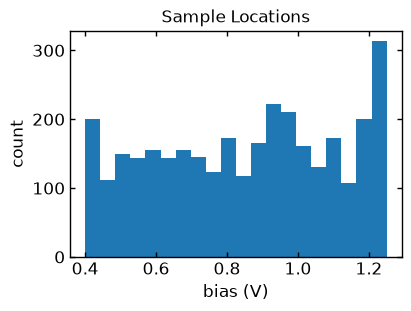

In [7]:
plot_hist_series(spectrum_series.flatten(), bins=20,
                 xlabel="bias (V)",
                 title="Sample Locations",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_samples.pdf"))

In [8]:
t_series = load_np_val(data_dir, 't_n_spectr_series_100_Ibeem.npy')

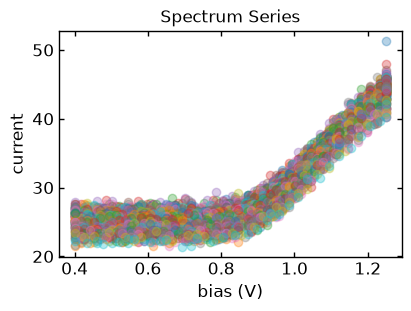

In [9]:
plot_spectrum_series_sort(spectrum_series, t_series, xlabel="bias (V)", ylabel="current", title="Spectrum Series")

In [10]:
in_min = 0.
in_max = .2
out_min = 0.
out_max = 100.

In [11]:
t_series_inv = rescale_bounds_inv(t_series, in_min, in_max, out_min, out_max)

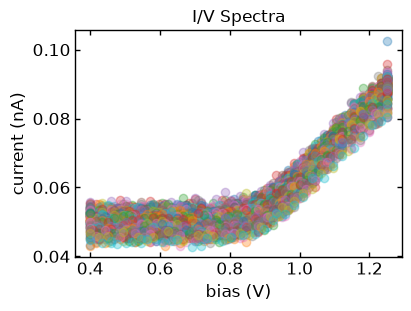

In [12]:
plot_spectrum_series_sort(spectrum_series, t_series_inv,
                          xlabel="bias (V)",
                          ylabel="current (nA)",
                          title="I/V Spectra",
                          f_save=join(figure_dir, "PRISMA_nanonis_33_spectrum.pdf"))

# Barrier

In [13]:
m_prior_series = load_np_val(data_dir, 'm_prior_spectr_series_100_Ibeem.npy')

In [14]:
barrier_fit = m_prior_series[:, -1, 1]

In [15]:
barrier_fit

array([0.88088863, 0.8640778 , 0.86763403, 0.87004164, 0.86648487,
       0.86855849, 0.87086392, 0.86896114, 0.87181093, 0.86243162,
       0.86367831, 0.85873031, 0.87020084, 0.86516506, 0.87215652,
       0.86744612, 0.87463241, 0.87282935, 0.87891793, 0.88062059,
       0.87082286, 0.85604364, 0.86684967, 0.85982803, 0.87440335,
       0.87831309, 0.87319244, 0.87173732, 0.86753871, 0.87434698,
       0.86297988, 0.8680548 , 0.86492189, 0.8686623 , 0.8705024 ,
       0.8672752 , 0.8729411 , 0.87713555, 0.88029692, 0.86745667,
       0.88741103, 0.8659078 , 0.87251604, 0.86842002, 0.86231836,
       0.86684401, 0.86314386, 0.86675725, 0.87553161, 0.87196216,
       0.87237144, 0.86023901, 0.87215168, 0.86833891, 0.87551285,
       0.87230189, 0.86901836, 0.87140739, 0.87512906, 0.87402536,
       0.86161135, 0.87132573, 0.85867837, 0.86815642, 0.8778546 ,
       0.86452627, 0.8807109 , 0.87195287, 0.87461093, 0.87186295,
       0.87364232, 0.87047075, 0.87307565, 0.87209425, 0.86753

In [16]:
np.mean(barrier_fit)

np.float64(0.8710989923533354)

In [17]:
np.std(barrier_fit)

np.float64(0.005859117301107444)

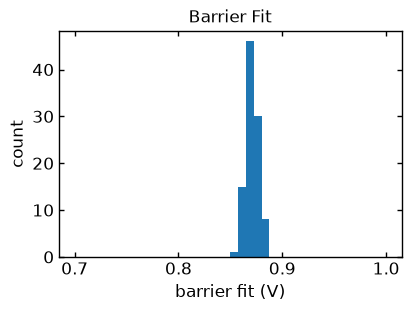

In [18]:
plot_hist_series(barrier_fit, bins=40, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                 title="Barrier Fit",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_barrier.pdf"))

# Confidence Posterior

In [19]:
var_prior_series = load_np_val(data_dir, 'var_prior_spectr_series100_Ibeem.npy')

In [20]:
barrier_stddev = np.sqrt(var_prior_series[:, -1, 1, 1])

In [21]:
barrier_stddev

array([0.01858733, 0.02317365, 0.02327755, 0.02290155, 0.02295538,
       0.02275581, 0.02333777, 0.0229977 , 0.02315193, 0.02294966,
       0.02266796, 0.0240703 , 0.02364283, 0.02396898, 0.02302651,
       0.02301649, 0.02358973, 0.02417962, 0.02318709, 0.02253547,
       0.02434395, 0.02403595, 0.02270966, 0.0236187 , 0.0217499 ,
       0.02279381, 0.02124307, 0.02143918, 0.02249255, 0.02200392,
       0.02361035, 0.02329967, 0.02304752, 0.02297121, 0.02206157,
       0.02373421, 0.02220402, 0.02277618, 0.02188438, 0.02247779,
       0.0202327 , 0.02301374, 0.02163002, 0.02270858, 0.02286984,
       0.02194481, 0.0231461 , 0.02317363, 0.02199842, 0.02194575,
       0.02160287, 0.02214537, 0.02184236, 0.02219267, 0.02236847,
       0.02188575, 0.02101227, 0.02314082, 0.02161014, 0.02159783,
       0.02307884, 0.02235315, 0.02398855, 0.02250759, 0.02208704,
       0.02294443, 0.02185216, 0.02194672, 0.0225333 , 0.0231168 ,
       0.02182945, 0.02189471, 0.0217698 , 0.02156285, 0.02160

In [22]:
np.mean(barrier_stddev)

np.float64(0.022413750915503863)

In [23]:
np.std(barrier_stddev)

np.float64(0.0009806417637334842)

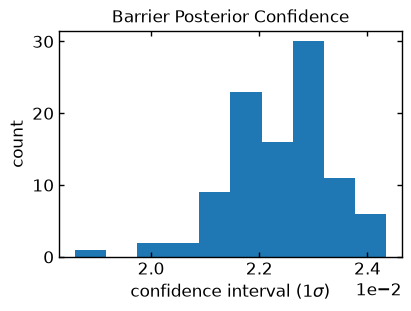

In [24]:
plot_hist_series(barrier_stddev, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                 title="Barrier Posterior Confidence",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_barrier_stddev_posterior.pdf"))

# Confidence NLR

In [25]:
p0 = [23., .8, 5e-3]

In [26]:
w_cf_series_np, w_cov_cf_series_np = curve_fit_series(spectrum_series, t_series, p0, Ibeem_vector)

In [27]:
barrier_cf = w_cf_series_np[:, 1]

In [28]:
barrier_cf

array([0.89090949, 0.8661593 , 0.86663653, 0.87007431, 0.8645953 ,
       0.86993556, 0.87184089, 0.87034719, 0.87418318, 0.86246344,
       0.8619853 , 0.85503426, 0.86962058, 0.86482812, 0.8704603 ,
       0.86731697, 0.87329802, 0.86829698, 0.879689  , 0.88074137,
       0.86661481, 0.85190755, 0.86866641, 0.85994827, 0.87652892,
       0.88202874, 0.87479477, 0.87564979, 0.86910165, 0.87665472,
       0.86142573, 0.86996649, 0.86350255, 0.87030585, 0.87185272,
       0.8681081 , 0.87433061, 0.88102563, 0.88372779, 0.868963  ,
       0.89200454, 0.86432275, 0.87769535, 0.86968503, 0.86170706,
       0.86986693, 0.86316116, 0.86940302, 0.87680224, 0.87429657,
       0.87428569, 0.85944546, 0.87536259, 0.86919641, 0.87839541,
       0.87422622, 0.86966361, 0.87334194, 0.87756003, 0.87580231,
       0.86340542, 0.87329871, 0.85791918, 0.86963515, 0.88308445,
       0.86534988, 0.88494894, 0.87285029, 0.87954187, 0.87193117,
       0.87550116, 0.87384866, 0.8768824 , 0.87486714, 0.86958

In [29]:
np.mean(barrier_cf)

np.float64(0.8725466739292236)

In [30]:
np.std(barrier_cf)

np.float64(0.007329479731804205)

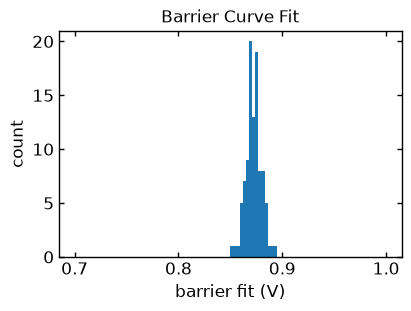

In [31]:
plot_hist_series(barrier_cf, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Curve Fit")

In [32]:
barrier_stddev_cf = np.sqrt(w_cov_cf_series_np[:, 1, 1])

In [33]:
barrier_stddev_cf

array([0.01336886, 0.00765823, 0.00659693, 0.0067716 , 0.00815389,
       0.00617317, 0.00734293, 0.00540674, 0.00762464, 0.00684537,
       0.00670399, 0.00785898, 0.00816943, 0.00909308, 0.00766159,
       0.00880447, 0.00679716, 0.00599361, 0.00777596, 0.00789824,
       0.00890253, 0.00634757, 0.00625687, 0.00480856, 0.00636166,
       0.00770867, 0.00630282, 0.00630474, 0.00892952, 0.00654453,
       0.00752591, 0.00690289, 0.00738122, 0.00717596, 0.00631053,
       0.00700135, 0.00788473, 0.00524654, 0.00511621, 0.00629531,
       0.0047184 , 0.00730987, 0.00675346, 0.00711917, 0.00667392,
       0.00660689, 0.00859183, 0.00658342, 0.00658232, 0.00766416,
       0.00538842, 0.00639294, 0.0068743 , 0.00807003, 0.00767527,
       0.00719879, 0.00552737, 0.00743863, 0.00575988, 0.00632982,
       0.00645564, 0.00666869, 0.0056133 , 0.00841166, 0.00689754,
       0.00641162, 0.00661405, 0.00750576, 0.00649715, 0.00711843,
       0.00775494, 0.00775541, 0.00450606, 0.00736979, 0.00567

In [34]:
np.mean(barrier_stddev_cf)

np.float64(0.006951718996626998)

In [35]:
np.std(barrier_stddev_cf)

np.float64(0.001332173393719814)

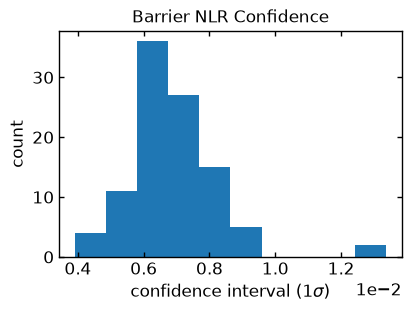

In [36]:
plot_hist_series(barrier_stddev_cf, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                 title="Barrier NLR Confidence",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_barrier_stddev_NLR.pdf"))

# Confidence FIM

In [37]:
series_ct = len(spectrum_series)
param_ct = m_prior_series.shape[2]

In [38]:
m_prior_cov_ML_series = np.empty((series_ct, param_ct, param_ct))
for i in range(series_ct):
    m_prior_cov_ML_series[i] = get_ML_cov_sp(Ibeem_vector_f_w_vectorized, spectrum_series[i], m_prior_series[i, -1], t_n=t_series[i], absolute_sigma=False)

In [39]:
# save_np_val(data_dir, 'm_prior_cov_ML_spectr_series_100_Ibeem.npy', m_prior_cov_ML_series)

In [40]:
barrier_stddev_ML = np.sqrt(m_prior_cov_ML_series[:, 1, 1])

In [41]:
barrier_stddev_ML

array([0.01381585, 0.00770711, 0.00657887, 0.00677479, 0.00809708,
       0.00620921, 0.00736199, 0.0054378 , 0.00760678, 0.00684889,
       0.00670904, 0.00775981, 0.00814986, 0.00908296, 0.00768578,
       0.00878989, 0.00673957, 0.00599329, 0.00780362, 0.00789942,
       0.00879657, 0.00629495, 0.00629893, 0.00480678, 0.00643241,
       0.00779482, 0.00634941, 0.00640143, 0.00898505, 0.00660376,
       0.00749383, 0.00695747, 0.00735207, 0.00722523, 0.00634137,
       0.00701904, 0.00795488, 0.00534918, 0.00526396, 0.00633905,
       0.00489666, 0.00730452, 0.0069964 , 0.00714959, 0.0066599 ,
       0.00671202, 0.00859969, 0.00666233, 0.00661771, 0.00776687,
       0.00544337, 0.00637529, 0.00703578, 0.00810009, 0.00779682,
       0.00728644, 0.00553901, 0.00743426, 0.00584826, 0.00641123,
       0.00650333, 0.00667434, 0.00559667, 0.0084598 , 0.00706474,
       0.00641266, 0.00682354, 0.00752092, 0.00671063, 0.00712475,
       0.00785127, 0.00793104, 0.00463462, 0.00750003, 0.00574

In [42]:
np.mean(barrier_stddev_ML)

np.float64(0.007016316978725786)

In [43]:
np.std(barrier_stddev_ML)

np.float64(0.001330579761605534)

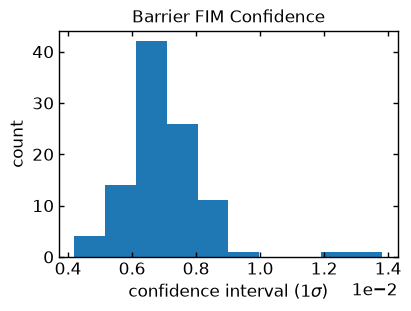

In [44]:
plot_hist_series(barrier_stddev_ML, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                 title="Barrier FIM Confidence",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_barrier_stddev_FIM.pdf"))

# Optimize Posterior

In [45]:
sigma_f = 2.
var_f = sigma_f**2 # function variance
beta = (1. / var_f) # function precision

In [46]:
measure_ct = spectrum_series.shape[1]

In [47]:
m_opt_series = np.empty((series_ct, param_ct))
var_opt_series = np.empty((series_ct, param_ct, param_ct))
Phi_opt_series = np.empty((series_ct, measure_ct, param_ct))
for i in range(series_ct):
    Phi_opt_series[i], m_opt_series[i], var_opt_series[i] \
        = optimize_posterior(beem_integral_f_vector_j,
                             beta, spectrum_series[i], t_series[i],
                             m_prior_series[i, 0], var_prior_series[i, 0],
                             eps=1e-4, i_max=1000)

In [48]:
barrier_fit_opt = m_opt_series[:, 1]

In [49]:
barrier_fit_opt

array([0.89077807, 0.86593726, 0.86651028, 0.86991625, 0.86438117,
       0.86975379, 0.8717031 , 0.87017638, 0.87394568, 0.86234327,
       0.86187605, 0.85492155, 0.86951895, 0.86462003, 0.87031344,
       0.86715572, 0.87307601, 0.8681675 , 0.87959842, 0.88054419,
       0.86651318, 0.85177449, 0.86856807, 0.85982891, 0.87642643,
       0.88186933, 0.87459939, 0.87544509, 0.86900711, 0.87644509,
       0.86131332, 0.8698703 , 0.86352729, 0.87016759, 0.87169267,
       0.86801596, 0.87425361, 0.88082586, 0.88358344, 0.86883516,
       0.89179642, 0.8641782 , 0.87754315, 0.86950915, 0.86160632,
       0.869714  , 0.86306764, 0.86922765, 0.87666335, 0.87412964,
       0.87404973, 0.859324  , 0.87516464, 0.86903228, 0.87821545,
       0.8740063 , 0.86949985, 0.87310747, 0.87739487, 0.87570879,
       0.86327207, 0.87308206, 0.85780226, 0.86943607, 0.88285088,
       0.86517277, 0.88477469, 0.87267253, 0.87940123, 0.87179116,
       0.87536388, 0.87370926, 0.87667774, 0.87471366, 0.86938

In [50]:
np.mean(barrier_fit_opt)

np.float64(0.8723932483194798)

In [51]:
np.std(barrier_fit_opt)

np.float64(0.0073136881872407815)

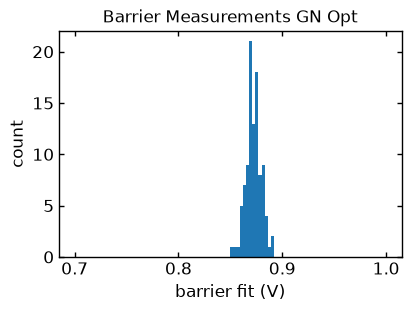

In [52]:
plot_hist_series(barrier_fit_opt, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Measurements GN Opt")

In [53]:
barrier_stddev_opt = np.sqrt(var_opt_series[:, 1, 1])

In [54]:
barrier_stddev_opt

array([0.02093926, 0.02371587, 0.02426334, 0.02357945, 0.02486049,
       0.02359562, 0.02369678, 0.02342822, 0.02374295, 0.02364647,
       0.02395025, 0.02566257, 0.02450375, 0.02462361, 0.02406456,
       0.02339713, 0.02499543, 0.02600837, 0.02386017, 0.02371467,
       0.02609694, 0.02553881, 0.02288885, 0.02408275, 0.02217887,
       0.02292432, 0.02210489, 0.02174227, 0.02313388, 0.02255794,
       0.02450766, 0.02329748, 0.02395982, 0.02319682, 0.0225138 ,
       0.02404651, 0.02275536, 0.02286698, 0.02189002, 0.02299151,
       0.02094534, 0.02403789, 0.02161905, 0.02339615, 0.02398441,
       0.02199475, 0.02371486, 0.02360519, 0.02225396, 0.02236011,
       0.02227179, 0.02323783, 0.02204783, 0.02310974, 0.02243102,
       0.02257047, 0.02193164, 0.0234058 , 0.02215591, 0.02193447,
       0.02342425, 0.02272536, 0.02463086, 0.02270001, 0.02192384,
       0.02367103, 0.02214648, 0.02313148, 0.02245879, 0.02369181,
       0.02218799, 0.02255726, 0.02166628, 0.02159499, 0.02237

In [55]:
np.mean(barrier_stddev_opt)

np.float64(0.023008341539458334)

In [56]:
np.std(barrier_stddev_opt)

np.float64(0.0012324063383224886)

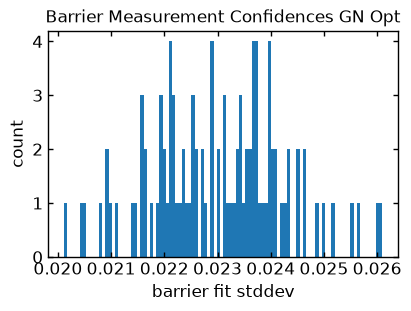

In [57]:
plot_hist_series(barrier_stddev_opt, bins=100, xlabel="barrier fit stddev", title="Barrier Measurement Confidences GN Opt")

In [58]:
# save_np_val(data_dir, 'Phi_opt_spectr_series_100_Ibeem.npy', Phi_opt_series)

In [59]:
# save_np_val(data_dir, 'm_opt_spectr_series_100_Ibeem.npy', m_opt_series)

In [60]:
# save_np_val(data_dir, 'var_opt_spectr_series_100_Ibeem.npy', var_opt_series)

# Optimize Posterior Pre-Trained

In [61]:
m_pt = np.mean(m_prior_series[:, -1], axis=0)

In [62]:
var_pt = np.diag(np.std(m_prior_series[:, -1], axis=0)**2)

In [63]:
m_opt_pt_series = np.empty((series_ct, param_ct))
var_opt_pt_series = np.empty((series_ct, param_ct, param_ct))
Phi_opt_pt_series = np.empty((series_ct, measure_ct, param_ct))
for i in range(series_ct):
    Phi_opt_pt_series[i], m_opt_pt_series[i], var_opt_pt_series[i] \
        = optimize_posterior(beem_integral_f_vector_j,
                             beta, spectrum_series[i], t_series[i],
                             m_pt, var_pt,
                             eps=1e-4, i_max=1000)

In [64]:
barrier_fit_opt_pt = m_opt_pt_series[:, 1]

In [65]:
barrier_fit_opt_pt

array([0.89052841, 0.86622772, 0.86678446, 0.87019933, 0.86465439,
       0.87002494, 0.871966  , 0.87076513, 0.87366543, 0.8625925 ,
       0.8621294 , 0.85534424, 0.86983607, 0.86490873, 0.872384  ,
       0.86739144, 0.87413614, 0.86848495, 0.87931823, 0.8805333 ,
       0.86688238, 0.85205625, 0.86880778, 0.86009306, 0.87619287,
       0.88159952, 0.87438125, 0.8752358 , 0.87097925, 0.87622357,
       0.86160159, 0.87048639, 0.86362144, 0.87097391, 0.87147266,
       0.87053679, 0.87399522, 0.88056014, 0.88338732, 0.86909114,
       0.89159299, 0.8644725 , 0.87731714, 0.8706426 , 0.86185605,
       0.8694808 , 0.8636556 , 0.86950791, 0.87646704, 0.87388292,
       0.87383144, 0.85954865, 0.87495591, 0.86927701, 0.87799383,
       0.87375403, 0.8694813 , 0.87287203, 0.87718047, 0.87546445,
       0.86349983, 0.87246987, 0.85807646, 0.86965255, 0.88262382,
       0.86544384, 0.88453645, 0.87058465, 0.87915543, 0.8720646 ,
       0.87516397, 0.87349439, 0.87647145, 0.87450075, 0.86852

In [66]:
np.mean(barrier_fit_opt_pt)

np.float64(0.8724826479236161)

In [67]:
np.std(barrier_fit_opt_pt)

np.float64(0.007111024048351565)

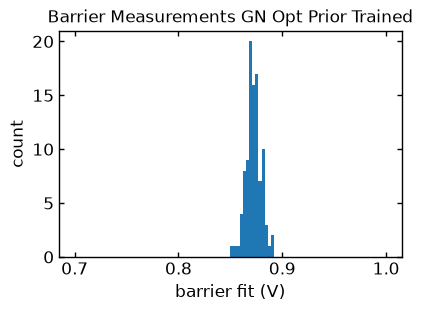

In [68]:
plot_hist_series(barrier_fit_opt_pt, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Measurements GN Opt Prior Trained")

In [69]:
barrier_stddev_opt_pt = np.sqrt(var_opt_pt_series[:, 1, 1])

In [70]:
barrier_stddev_opt_pt

array([0.00541179, 0.00551902, 0.00552591, 0.00550286, 0.00554419,
       0.00550546, 0.00551996, 0.00551001, 0.00551595, 0.00552674,
       0.00554079, 0.00556214, 0.00553019, 0.00554228, 0.00553237,
       0.00552318, 0.00554099, 0.00556352, 0.00551742, 0.00552021,
       0.00556771, 0.00557155, 0.00550816, 0.00552682, 0.00548189,
       0.00549362, 0.00548562, 0.00546517, 0.00550935, 0.00549704,
       0.00553833, 0.00550446, 0.00552398, 0.00550949, 0.0054983 ,
       0.00551489, 0.00549601, 0.00548665, 0.00546789, 0.00550713,
       0.00543275, 0.00552287, 0.00546395, 0.00550648, 0.00552345,
       0.00548478, 0.00551818, 0.00550753, 0.00548982, 0.00548044,
       0.00548921, 0.00552297, 0.00548293, 0.00550148, 0.00549055,
       0.00549653, 0.00548554, 0.00550708, 0.00548398, 0.0054773 ,
       0.00551245, 0.00550317, 0.00554071, 0.0055018 , 0.00547261,
       0.00550732, 0.00546657, 0.0054926 , 0.00547938, 0.00552033,
       0.00548183, 0.00548386, 0.00546554, 0.00546481, 0.00547

In [71]:
np.mean(barrier_stddev_opt_pt)

np.float64(0.005499120830963602)

In [72]:
np.std(barrier_stddev_opt_pt)

np.float64(3.3730802899681464e-05)

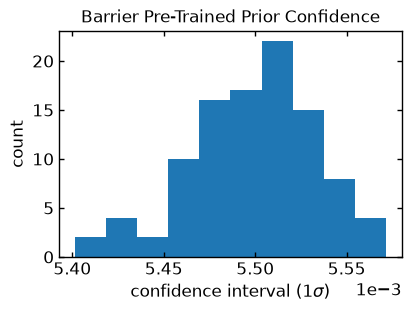

In [73]:
plot_hist_series(barrier_stddev_opt_pt, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                 title="Barrier Pre-Trained Prior Confidence",
                 f_save=join(figure_dir, "PRISMA_nanonis_33_barrier_stddev_opt_pretrain.pdf"))

In [74]:
# save_np_val(data_dir, 'Phi_opt_pt_spectr_series_100_Ibeem.npy', Phi_opt_pt_series)

In [75]:
# save_np_val(data_dir, 'm_opt_pt_spectr_series_100_Ibeem.npy', m_opt_pt_series)

In [76]:
# save_np_val(data_dir, 'var_opt_pt_spectr_series_100_Ibeem.npy', var_opt_pt_series)